In [56]:
import h5netcdf

print("h5netcdf imported successfully!")

h5netcdf imported successfully!


In [57]:
import sys
import types

# Implement Fletcher32 checksum in pure Python
class Fletcher32:
    def encode(self, data):
        data = bytes(data)

        if len(data) % 2:
            data += b"\x00"

        sum1 = 0
        sum2 = 0

        for i in range(0, len(data), 2):
            word = (data[i] << 8) | data[i + 1]
            sum1 = (sum1 + word) % 65535
            sum2 = (sum2 + sum1) % 65535

        checksum = (sum2 << 16) | sum1

        return bytes(data[:len(data) - (len(data) % 2)]) + (
            (checksum >> 16).to_bytes(2, "big")
            + (checksum & 0xFFFF).to_bytes(2, "big")
        )


# Create a temporary compatibility module
numcodecs_shim = types.ModuleType("numcodecs")
numcodecs_shim.Fletcher32 = Fletcher32

sys.modules["numcodecs"] = numcodecs_shim

print("Project-local Fletcher32 compatibility shim loaded.")

Project-local Fletcher32 compatibility shim loaded.


In [58]:
import pyfive
print("PyFive imported successfully!")

PyFive imported successfully!


In [59]:
with pyfive.File(sample_file, "r") as ds:

    print("Root contents:")
    for name, item in ds.items():
        print(name, type(item))

    print("\nGlobal attributes:")
    print(ds.attrs)

Root contents:
htime <class 'pyfive.high_level.Dataset'>
lat <class 'pyfive.high_level.Dataset'>
lon <class 'pyfive.high_level.Dataset'>
fname <class 'pyfive.high_level.Dataset'>
sid <class 'pyfive.high_level.Dataset'>
NomDate <class 'pyfive.high_level.Dataset'>
NomTime <class 'pyfive.high_level.Dataset'>
sss <class 'pyfive.high_level.Dataset'>
nchan <class 'pyfive.high_level.Dataset'>
SubSatLat <class 'pyfive.high_level.Dataset'>
SubSatLon <class 'pyfive.high_level.Dataset'>
WindSpd <class 'pyfive.high_level.Dataset'>
CentPrs <class 'pyfive.high_level.Dataset'>
CentLat <class 'pyfive.high_level.Dataset'>
CentLon <class 'pyfive.high_level.Dataset'>
VZA <class 'pyfive.high_level.Dataset'>
VSCHN <class 'pyfive.high_level.Dataset'>
IRWIN <class 'pyfive.high_level.Dataset'>
IRWVP <class 'pyfive.high_level.Dataset'>
archer_lat <class 'pyfive.high_level.Dataset'>
archer_lon <class 'pyfive.high_level.Dataset'>
archer_combo_score <class 'pyfive.high_level.Dataset'>
archer_ring_score <class 'py

eye_prob <class 'pyfive.high_level.Dataset'>
eye_comp <class 'pyfive.high_level.Dataset'>
rad_eye <class 'pyfive.high_level.Dataset'>
rad_eye_con1 <class 'pyfive.high_level.Dataset'>
rad_eye_con2 <class 'pyfive.high_level.Dataset'>
eye_conf <class 'pyfive.high_level.Dataset'>
rad_eyewall <class 'pyfive.high_level.Dataset'>
bt_eye <class 'pyfive.high_level.Dataset'>
bt_eyewall <class 'pyfive.high_level.Dataset'>
odt84 <class 'pyfive.high_level.Dataset'>
vlat <class 'pyfive.high_level.Dataset'>
vlon <class 'pyfive.high_level.Dataset'>
var_icen <class 'pyfive.high_level.Dataset'>
ang_icen <class 'pyfive.high_level.Dataset'>
tavg_icen <class 'pyfive.high_level.Dataset'>
tmin_icen <class 'pyfive.high_level.Dataset'>
tmax_icen <class 'pyfive.high_level.Dataset'>
tstd_icen <class 'pyfive.high_level.Dataset'>
tnum_icen <class 'pyfive.high_level.Dataset'>
var_acen <class 'pyfive.high_level.Dataset'>
ang_acen <class 'pyfive.high_level.Dataset'>
tavg_acen <class 'pyfive.high_level.Dataset'>
tmin_

In [60]:
with pyfive.File(sample_file, "r") as ds:

    print("VARIABLE DETAILS\n")

    for name, variable in ds.items():
        print(
            f"{name:25} "
            f"Shape: {variable.shape} "
            f"Data type: {variable.dtype}"
        )

VARIABLE DETAILS

htime                     Shape: (1,) Data type: float64
lat                       Shape: (301,) Data type: float32
lon                       Shape: (301,) Data type: float32


fname                     Shape: (1, 128) Data type: |S1
sid                       Shape: (1, 13) Data type: |S1
NomDate                   Shape: (1,) Data type: int32
NomTime                   Shape: (1,) Data type: int32
sss                       Shape: (1,) Data type: int32
nchan                     Shape: (1,) Data type: int32
SubSatLat                 Shape: (1,) Data type: float32
SubSatLon                 Shape: (1,) Data type: float32
WindSpd                   Shape: (1,) Data type: float32
CentPrs                   Shape: (1,) Data type: float32
CentLat                   Shape: (1,) Data type: float32
CentLon                   Shape: (1,) Data type: float32
VZA                       Shape: (1,) Data type: float32
VSCHN                     Shape: (1, 301, 301) Data type: int16
IRWIN                     Shape: (1, 301, 301) Data type: int16
IRWVP                     Shape: (1, 301, 301) Data type: int16
archer_lat                Shape: (1,) Data type: float32
archer_lon         

Image shape: (301, 301)
Minimum value: -358
Maximum value: 10754
Mean value: 8481.288495711968


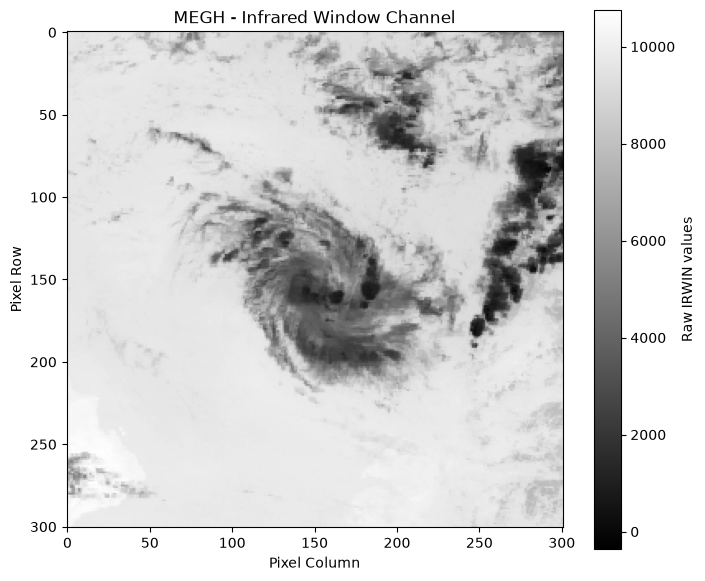

In [61]:
with pyfive.File(sample_file, "r") as ds:
    ir_image = np.array(ds["IRWIN"][0, :, :])

print("Image shape:", ir_image.shape)
print("Minimum value:", np.min(ir_image))
print("Maximum value:", np.max(ir_image))
print("Mean value:", np.mean(ir_image))

plt.figure(figsize=(8, 7))
plt.imshow(ir_image, cmap="gray")
plt.colorbar(label="Raw IRWIN values")
plt.title("MEGH - Infrared Window Channel")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")
plt.show()

In [62]:
from pathlib import Path

megh_folder = Path("../raw/HURSAT_b1_v06_2015309N14067_MEGH_c20170721")
sample_file = sorted(megh_folder.rglob("*.nc"))[0]

print("File:", sample_file.name)
print("Size:", round(sample_file.stat().st_size / (1024 * 1024), 2), "MB")

File: 2015309N14067.MEGH.2015.11.04.1200.20.MET-7.018.hursat-b1.v06.nc
Size: 0.32 MB


In [63]:
import importlib.util

for package in ["pip", "numpy", "pandas", "h5netcdf", "pyfive"]:
    print(package, importlib.util.find_spec(package) is not None)

pip True
numpy True
pandas True
h5netcdf True
pyfive True


In [67]:
from pathlib import Path
import importlib.util

spec = importlib.util.find_spec("pyfive")
print("PyFive location:", spec.origin)

PyFive location: c:\Users\Sreoshi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyfive\__init__.py


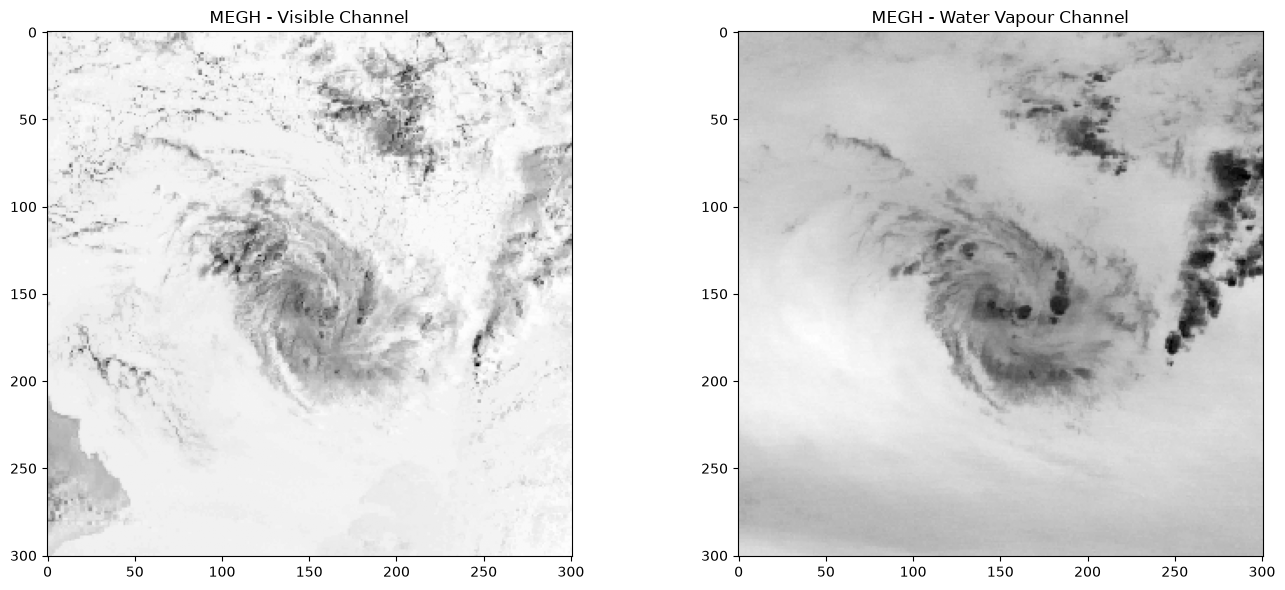

In [ ]:
with pyfive.File(sample_file, "r") as ds:
    visible_image = np.array(ds["VSCHN"][0, :, :])
    water_vapor_image = np.array(ds["IRWVP"][0, :, :])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(visible_image, cmap="gray")
axes[0].set_title("MEGH - Visible Channel")

axes[1].imshow(water_vapor_image, cmap="gray")
axes[1].set_title("MEGH - Water Vapour Channel")

plt.tight_layout()
plt.show()

In [ ]:
with pyfive.File(sample_file, "r") as ds:

    metadata_fields = [
        "NomDate",
        "NomTime",
        "CentLat",
        "CentLon",
        "WindSpd",
        "CentPrs",
        "archer_lat",
        "archer_lon",
        "archer_combo_score",
        "archer_ring_score"
    ]

    for field in metadata_fields:
        if field in ds:
            print(f"{field}: {np.array(ds[field][...])}")

NomDate: [115308]
NomTime: [113000]
CentLat: [14.]
CentLon: [66.899994]
WindSpd: [17.6]
CentPrs: [1007.]
archer_lat: [15.775]
archer_lon: [65.9982]
archer_combo_score: [8.7412]
archer_ring_score: [1.2157]


In [74]:
import csv
import numpy as np
from pathlib import Path

records = []

metadata_fields = [
    "htime",
    "CentLat",
    "CentLon",
    "WindSpd",
    "CentPrs",
    "archer_lat",
    "archer_lon",
    "archer_combo_score",
    "archer_ring_score"
]

for file_path in nc_files:

    with pyfive.File(file_path, "r") as ds:

        record = {"filename": file_path.name}

        for field in metadata_fields:
            if field in ds:
                values = np.array(ds[field][...]).flatten()
                record[field] = values[0].item()

        records.append(record)

print("Total observations:", len(records))
print("\nFirst observation:")
print(records[0])

Total observations: 98

First observation:
{'filename': '2015309N14067.MEGH.2015.11.04.1200.20.MET-7.018.hursat-b1.v06.nc', 'htime': 16743.499999999534, 'CentLat': 14.0, 'CentLon': 66.89999389648438, 'WindSpd': 17.600000381469727, 'CentPrs': 1007.0, 'archer_lat': 15.774999618530273, 'archer_lon': 65.99819946289062, 'archer_combo_score': 8.74120044708252, 'archer_ring_score': 1.2157000303268433}


In [75]:
output_path = Path("../processed/megh_metadata.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=records[0].keys())
    writer.writeheader()
    writer.writerows(records)

print("Saved to:", output_path)

Saved to: ..\processed\megh_metadata.csv


In [77]:
import csv
from pathlib import Path

csv_path = Path("../processed/megh_metadata.csv")

with open(csv_path, "r", newline="") as file:
    reader = csv.DictReader(file)
    saved_records = list(reader)

print("CSV exists:", csv_path.exists())
print("Saved observations:", len(saved_records))
print("Columns:", reader.fieldnames)

CSV exists: True
Saved observations: 98
Columns: ['filename', 'htime', 'CentLat', 'CentLon', 'WindSpd', 'CentPrs', 'archer_lat', 'archer_lon', 'archer_combo_score', 'archer_ring_score']


In [78]:
from pathlib import Path

chapala_folder = Path("../raw/HURSAT_b1_v06_2015301N11065_CHAPALA_c20170721")

chapala_files = sorted(chapala_folder.glob("*.nc"))

print("CHAPALA NetCDF files:", len(chapala_files))
print("First file:", chapala_files[0].name if chapala_files else "No files found")

CHAPALA NetCDF files: 122
First file: 2015301N11065.CHAPALA.2015.10.27.1200.16.MET-7.022.hursat-b1.v06.nc


In [79]:
chapala_records = []

metadata_fields = [
    "htime",
    "CentLat",
    "CentLon",
    "WindSpd",
    "CentPrs",
    "archer_lat",
    "archer_lon",
    "archer_combo_score",
    "archer_ring_score"
]

for file_path in chapala_files:
    with pyfive.File(file_path, "r") as ds:
        record = {"filename": file_path.name}

        for field in metadata_fields:
            if field in ds:
                values = np.array(ds[field][...]).flatten()
                record[field] = values[0].item()

        chapala_records.append(record)

print("Total CHAPALA observations:", len(chapala_records))
print("\nFirst CHAPALA observation:")
print(chapala_records[0])

Total CHAPALA observations: 122

First CHAPALA observation:
{'filename': '2015301N11065.CHAPALA.2015.10.27.1200.16.MET-7.022.hursat-b1.v06.nc', 'htime': 16735.499999999534, 'CentLat': 10.699999809265137, 'CentLon': 65.10000610351562, 'WindSpd': 22.0, 'CentPrs': 1004.0, 'archer_lat': 10.100000381469727, 'archer_lon': 63.16640090942383, 'archer_combo_score': 9.98009967803955, 'archer_ring_score': 2.6366000175476074}


In [80]:
chapala_csv_path = Path("../processed/chapala_metadata.csv")
chapala_csv_path.parent.mkdir(parents=True, exist_ok=True)

with open(chapala_csv_path, "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=chapala_records[0].keys()
    )
    writer.writeheader()
    writer.writerows(chapala_records)

print("Saved to:", chapala_csv_path)

Saved to: ..\processed\chapala_metadata.csv


In [81]:
chapala_csv_path = Path("../processed/chapala_metadata.csv")

with open(chapala_csv_path, "r", newline="") as file:
    reader = csv.DictReader(file)
    saved_chapala = list(reader)

print("CSV exists:", chapala_csv_path.exists())
print("Saved observations:", len(saved_chapala))
print("Columns:", reader.fieldnames)

CSV exists: True
Saved observations: 122
Columns: ['filename', 'htime', 'CentLat', 'CentLon', 'WindSpd', 'CentPrs', 'archer_lat', 'archer_lon', 'archer_combo_score', 'archer_ring_score']


In [82]:
sample_file = nc_files[0]

with pyfive.File(sample_file, "r") as ds:
    for field in ["WindSpd", "CentPrs", "CentLat", "CentLon"]:
        print(f"\n{field}:")
        print(ds[field].attrs)


WindSpd:
{'long_name': np.bytes_(b'Wind Speed'), 'units': np.bytes_(b'knots'), 'valid_range': array([  0., 200.], dtype=float32), 'DIMENSION_LIST': array([array([<pyfive.core.Reference object at 0x000001B211BA0410>], dtype=object)],
      dtype=object), '_Netcdf4Dimid': np.int32(2)}

CentPrs:
{'long_name': np.bytes_(b'Central Pressure'), 'units': np.bytes_(b'mb'), 'valid_range': array([ 700., 1100.], dtype=float32), 'DIMENSION_LIST': array([array([<pyfive.core.Reference object at 0x000001B211BA0BE0>], dtype=object)],
      dtype=object), '_Netcdf4Dimid': np.int32(2)}

CentLat:
{'long_name': np.bytes_(b'Latitude of Tropical Cyclone Circulation Center'), 'units': np.bytes_(b'degrees_north'), 'valid_range': array([-90.,  90.], dtype=float32), 'DIMENSION_LIST': array([array([<pyfive.core.Reference object at 0x000001B211BA19A0>], dtype=object)],
      dtype=object), '_Netcdf4Dimid': np.int32(2)}

CentLon:
{'long_name': np.bytes_(b'Longitude of Tropical Cyclone Circulation Center'), 'units'

In [83]:
import numpy as np

def check_timestamps(records, cyclone_name):
    times = np.array([float(record["htime"]) for record in records])

    differences = np.diff(times)

    print(f"\n{cyclone_name}")
    print("-" * 35)
    print("Total observations:", len(times))
    print("Chronologically ordered:", np.all(differences >= 0))
    print("Duplicate timestamps:", np.sum(differences == 0))
    print("Earliest htime:", times.min())
    print("Latest htime:", times.max())

check_timestamps(records, "MEGH")
check_timestamps(chapala_records, "CHAPALA")


MEGH
-----------------------------------
Total observations: 98
Chronologically ordered: True
Duplicate timestamps: 49
Earliest htime: 16743.499999999534
Latest htime: 16749.499999999534

CHAPALA
-----------------------------------
Total observations: 122
Chronologically ordered: True
Duplicate timestamps: 61
Earliest htime: 16735.499999999534
Latest htime: 16742.999999999534


In [84]:
from collections import Counter

def inspect_duplicates(records, cyclone_name):
    times = [round(float(r["htime"]), 6) for r in records]
    counts = Counter(times)

    duplicates = {
        time: count
        for time, count in counts.items()
        if count > 1
    }

    print(f"\n{cyclone_name}")
    print("Duplicate timestamp count:", len(duplicates))
    print("First 5 duplicate timestamps:")

    for time, count in list(duplicates.items())[:5]:
        print(time, "->", count, "observations")

inspect_duplicates(records, "MEGH")
inspect_duplicates(chapala_records, "CHAPALA")


MEGH
Duplicate timestamp count: 49
First 5 duplicate timestamps:
16743.5 -> 2 observations
16743.625 -> 2 observations
16743.75 -> 2 observations
16743.875 -> 2 observations
16744.0 -> 2 observations

CHAPALA
Duplicate timestamp count: 61
First 5 duplicate timestamps:
16735.5 -> 2 observations
16735.625 -> 2 observations
16735.75 -> 2 observations
16735.875 -> 2 observations
16736.0 -> 2 observations


In [85]:
def compare_duplicate_records(records, cyclone_name):
    print(f"\n{cyclone_name} — First 3 duplicate pairs")
    print("=" * 70)

    seen = set()
    shown = 0

    for record in records:
        timestamp = round(float(record["htime"]), 6)

        if timestamp in seen:
            continue

        seen.add(timestamp)

        pair = [
            r for r in records
            if round(float(r["htime"]), 6) == timestamp
        ]

        if len(pair) == 2:
            print("\nTimestamp:", timestamp)

            for r in pair:
                print("Filename:", r["filename"])
                print("Wind:", r["WindSpd"], "knots")
                print("Pressure:", r["CentPrs"], "mb")
                print("Centre:", r["CentLat"], r["CentLon"])

            shown += 1

        if shown == 3:
            break

compare_duplicate_records(records, "MEGH")
compare_duplicate_records(chapala_records, "CHAPALA")


MEGH — First 3 duplicate pairs

Timestamp: 16743.5
Filename: 2015309N14067.MEGH.2015.11.04.1200.20.MET-7.018.hursat-b1.v06.nc
Wind: 17.600000381469727 knots
Pressure: 1007.0 mb
Centre: 14.0 66.89999389648438
Filename: 2015309N14067.MEGH.2015.11.04.1200.77.MSG-3.018.hursat-b1.v06.nc
Wind: 17.600000381469727 knots
Pressure: 1007.0 mb
Centre: 14.0 66.89999389648438

Timestamp: 16743.625
Filename: 2015309N14067.MEGH.2015.11.04.1500.20.MET-7.020.hursat-b1.v06.nc
Wind: 19.799999237060547 knots
Pressure: 1005.5 mb
Centre: 13.985833168029785 66.64250183105469
Filename: 2015309N14067.MEGH.2015.11.04.1500.77.MSG-3.020.hursat-b1.v06.nc
Wind: 19.799999237060547 knots
Pressure: 1005.5 mb
Centre: 13.985833168029785 66.64250183105469

Timestamp: 16743.75
Filename: 2015309N14067.MEGH.2015.11.04.1800.20.MET-7.022.hursat-b1.v06.nc
Wind: 22.0 knots
Pressure: 1004.0 mb
Centre: 14.0 66.39999389648438
Filename: 2015309N14067.MEGH.2015.11.04.1800.76.MSG-3.022.hursat-b1.v06.nc
Wind: 22.0 knots
Pressure: 1004

In [87]:
from collections import Counter

def satellite_distribution(records, cyclone_name):
    satellites = [
        record["filename"].split(".")[-5]
        for record in records
    ]

    print(f"\n{cyclone_name} satellite distribution:")
    for satellite, count in sorted(Counter(satellites).items()):
        print(f"{satellite}: {count}")

satellite_distribution(records, "MEGH")
satellite_distribution(chapala_records, "CHAPALA")


MEGH satellite distribution:
MET-7: 49
MSG-3: 49

CHAPALA satellite distribution:
MET-7: 61
MSG-3: 61


In [88]:
def check_satellite_pairs(records, cyclone_name):
    grouped = {}

    for record in records:
        timestamp = round(float(record["htime"]), 6)
        satellite = record["filename"].split(".")[-5]
        grouped.setdefault(timestamp, {})[satellite] = record

    fields = ["WindSpd", "CentPrs", "CentLat", "CentLon"]

    mismatches = []

    for timestamp, pair in grouped.items():
        if "MET-7" not in pair or "MSG-3" not in pair:
            mismatches.append((timestamp, "Missing satellite pair"))
            continue

        for field in fields:
            value1 = float(pair["MET-7"][field])
            value2 = float(pair["MSG-3"][field])

            if not np.isclose(value1, value2):
                mismatches.append((timestamp, field, value1, value2))

    print(f"\n{cyclone_name}")
    print("Total timestamp pairs:", len(grouped))
    print("Mismatches:", len(mismatches))
    print("First mismatches:", mismatches[:5])

check_satellite_pairs(records, "MEGH")
check_satellite_pairs(chapala_records, "CHAPALA")


MEGH
Total timestamp pairs: 49
Mismatches: 0
First mismatches: []

CHAPALA
Total timestamp pairs: 61
Mismatches: 0
First mismatches: []


In [89]:
def create_analysis_records(records):
    unique_records = {}
    for record in records:
        timestamp = round(float(record["htime"]), 6)

        if timestamp not in unique_records:
            unique_records[timestamp] = record

    return sorted(
        unique_records.values(),
        key=lambda r: float(r["htime"])
    )

megh_analysis = create_analysis_records(records)
chapala_analysis = create_analysis_records(chapala_records)

print("MEGH analysis observations:", len(megh_analysis))
print("CHAPALA analysis observations:", len(chapala_analysis))
print("Combined:", len(megh_analysis) + len(chapala_analysis))

MEGH analysis observations: 49
CHAPALA analysis observations: 61
Combined: 110


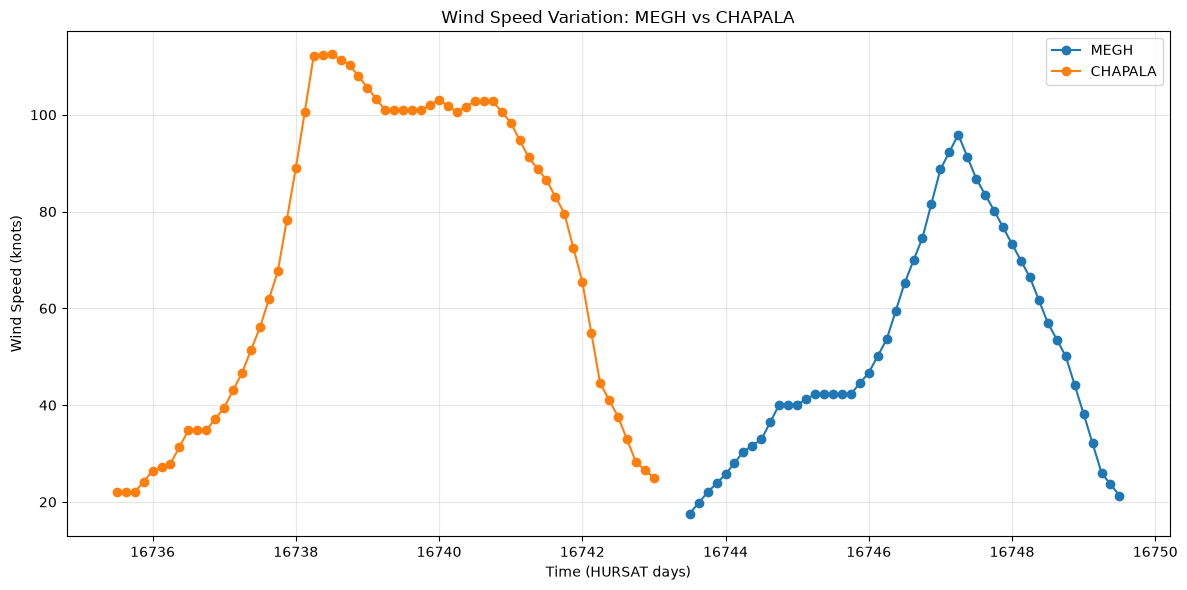

In [90]:
import matplotlib.pyplot as plt
import numpy as np

megh_time = np.array([float(r["htime"]) for r in megh_analysis])
megh_wind = np.array([float(r["WindSpd"]) for r in megh_analysis])

chapala_time = np.array([float(r["htime"]) for r in chapala_analysis])
chapala_wind = np.array([float(r["WindSpd"]) for r in chapala_analysis])

plt.figure(figsize=(12, 6))

plt.plot(megh_time, megh_wind, marker="o", label="MEGH")
plt.plot(chapala_time, chapala_wind, marker="o", label="CHAPALA")

plt.xlabel("Time (HURSAT days)")
plt.ylabel("Wind Speed (knots)")
plt.title("Wind Speed Variation: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

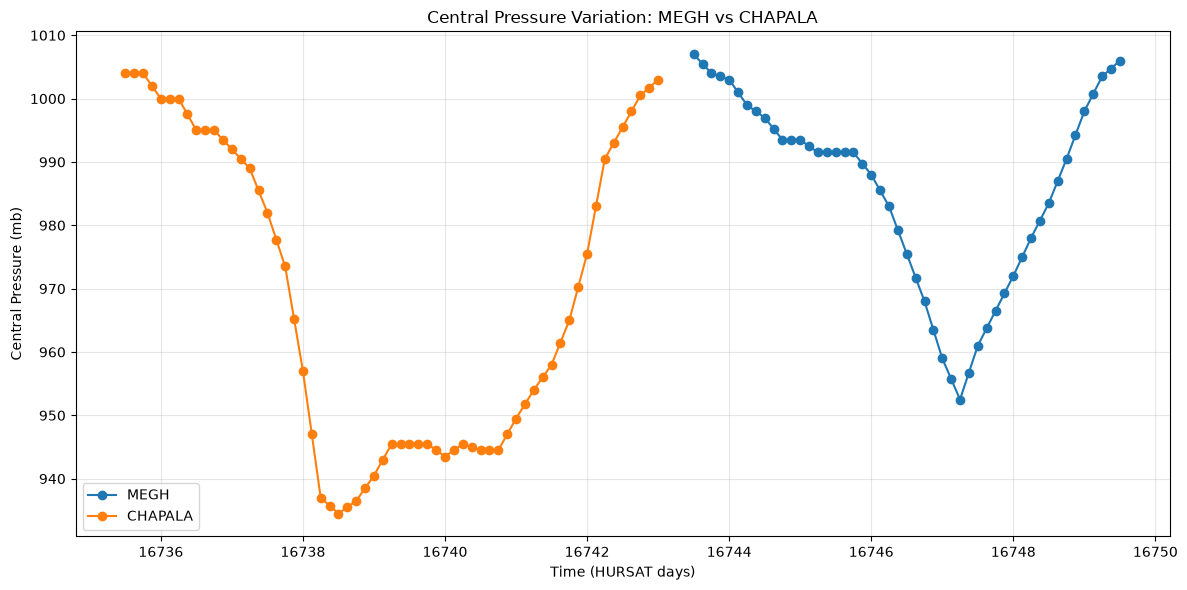

In [91]:
megh_pressure = np.array([
    float(r["CentPrs"]) for r in megh_analysis
])

chapala_pressure = np.array([
    float(r["CentPrs"]) for r in chapala_analysis
])

plt.figure(figsize=(12, 6))

plt.plot(megh_time, megh_pressure, marker="o", label="MEGH")
plt.plot(chapala_time, chapala_pressure, marker="o", label="CHAPALA")

plt.xlabel("Time (HURSAT days)")
plt.ylabel("Central Pressure (mb)")
plt.title("Central Pressure Variation: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

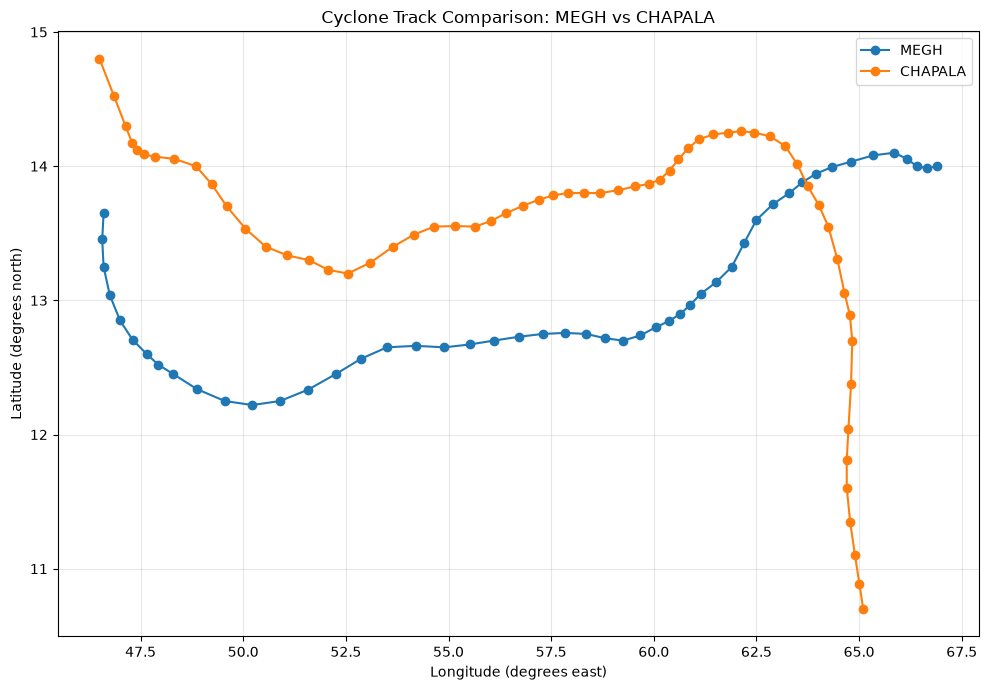

In [92]:
plt.figure(figsize=(10, 7))

plt.plot(
    [float(r["CentLon"]) for r in megh_analysis],
    [float(r["CentLat"]) for r in megh_analysis],
    marker="o",
    label="MEGH"
)

plt.plot(
    [float(r["CentLon"]) for r in chapala_analysis],
    [float(r["CentLat"]) for r in chapala_analysis],
    marker="o",
    label="CHAPALA"
)

plt.xlabel("Longitude (degrees east)")
plt.ylabel("Latitude (degrees north)")
plt.title("Cyclone Track Comparison: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

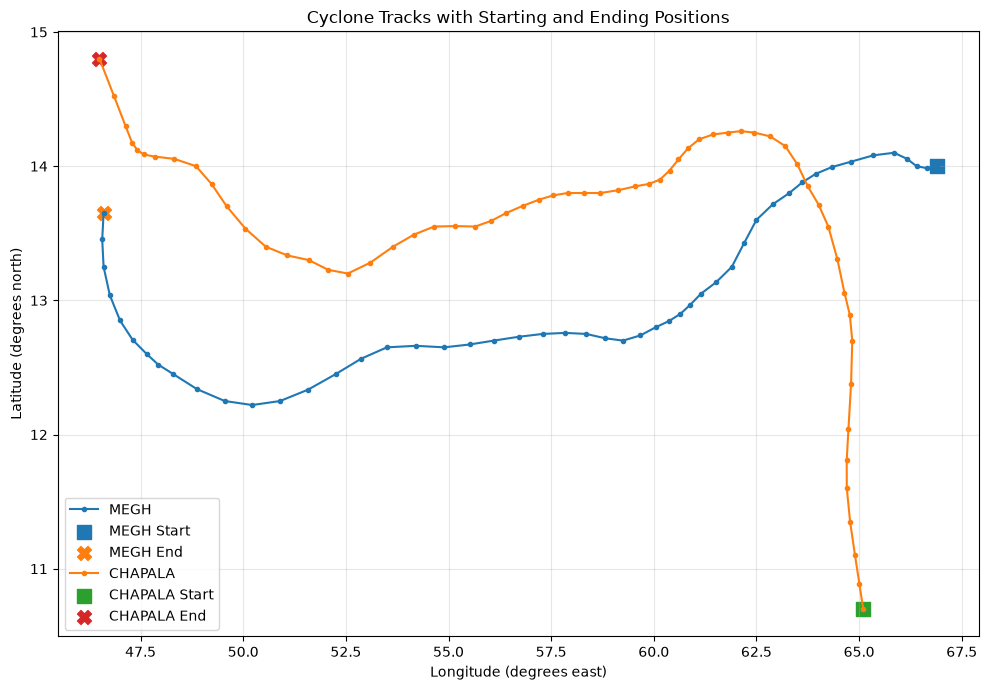

In [93]:
plt.figure(figsize=(10, 7))

for data, name in [
    (megh_analysis, "MEGH"),
    (chapala_analysis, "CHAPALA")
]:
    lon = [float(r["CentLon"]) for r in data]
    lat = [float(r["CentLat"]) for r in data]

    plt.plot(lon, lat, marker="o", markersize=3, label=name)
    plt.scatter(lon[0], lat[0], marker="s", s=100,
                label=f"{name} Start")
    plt.scatter(lon[-1], lat[-1], marker="X", s=100,
                label=f"{name} End")

plt.xlabel("Longitude (degrees east)")
plt.ylabel("Latitude (degrees north)")
plt.title("Cyclone Tracks with Starting and Ending Positions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
def calculate_statistics(data, cyclone_name):
    wind = np.array([float(r["WindSpd"]) for r in data])
    pressure = np.array([float(r["CentPrs"]) for r in data])

    print(f"\n{cyclone_name}")
    print("=" * 40)

    print("Wind Speed (knots)")
    print("Minimum:", round(wind.min(), 2))
    print("Maximum:", round(wind.max(), 2))
    print("Average:", round(wind.mean(), 2))

    print("\nCentral Pressure (mb)")
    print("Minimum:", round(pressure.min(), 2))
    print("Maximum:", round(pressure.max(), 2))
    print("Average:", round(pressure.mean(), 2))


calculate_statistics(megh_analysis, "MEGH")
calculate_statistics(chapala_analysis, "CHAPALA")


MEGH
Wind Speed (knots)
Minimum: 17.6
Maximum: 95.9
Average: 51.02

Central Pressure (mb)
Minimum: 952.5
Maximum: 1007.0
Average: 985.85

CHAPALA
Wind Speed (knots)
Minimum: 22.0
Maximum: 112.5
Average: 70.96

Central Pressure (mb)
Minimum: 934.5
Maximum: 1004.0
Average: 968.66


In [95]:
def inspect_archer_scores(data, cyclone_name):
    combo = np.array([
        float(r["archer_combo_score"]) for r in data
    ])

    ring = np.array([
        float(r["archer_ring_score"]) for r in data
    ])

    print(f"\n{cyclone_name}")
    print("=" * 40)

    print("ARCHER Combo Score")
    print("Minimum:", round(combo.min(), 3))
    print("Maximum:", round(combo.max(), 3))
    print("Average:", round(combo.mean(), 3))

    print("\nARCHER Ring Score")
    print("Minimum:", round(ring.min(), 3))
    print("Maximum:", round(ring.max(), 3))
    print("Average:", round(ring.mean(), 3))


inspect_archer_scores(megh_analysis, "MEGH")
inspect_archer_scores(chapala_analysis, "CHAPALA")


MEGH
ARCHER Combo Score
Minimum: -0.079
Maximum: 13.282
Average: 7.323

ARCHER Ring Score
Minimum: -0.445
Maximum: 6.946
Average: 1.957

CHAPALA
ARCHER Combo Score
Minimum: 2.8
Maximum: 10.925
Average: 6.514

ARCHER Ring Score
Minimum: -0.08
Maximum: 15.092
Average: 5.12


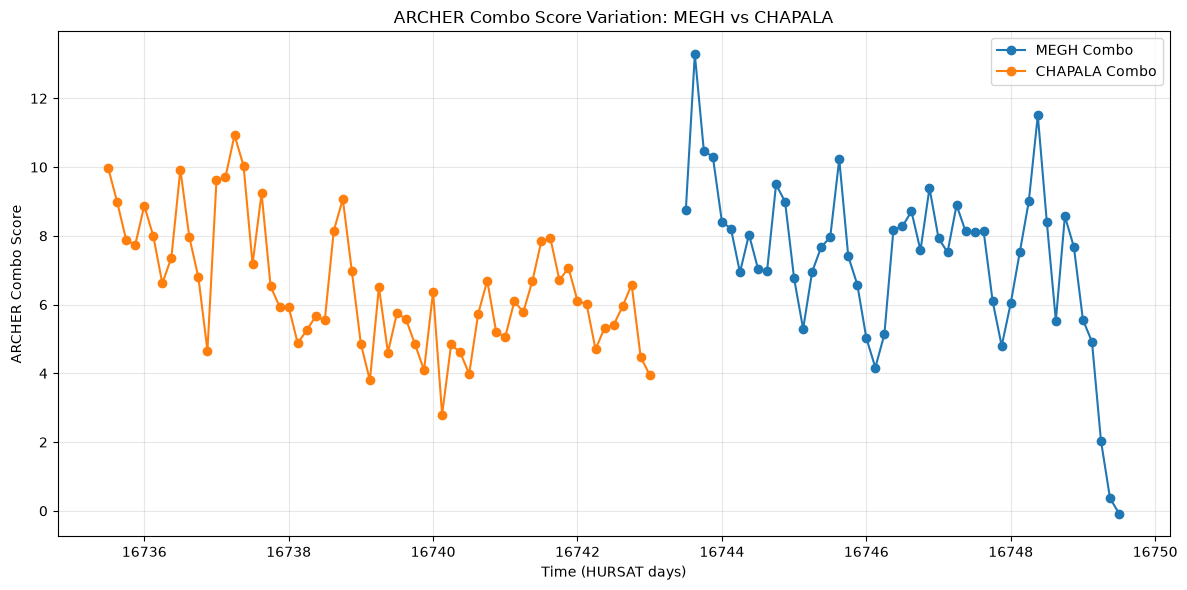

In [96]:
plt.figure(figsize=(12, 6))

plt.plot(
    megh_time,
    [float(r["archer_combo_score"]) for r in megh_analysis],
    marker="o",
    label="MEGH Combo"
)

plt.plot(
    chapala_time,
    [float(r["archer_combo_score"]) for r in chapala_analysis],
    marker="o",
    label="CHAPALA Combo"
)

plt.xlabel("Time (HURSAT days)")
plt.ylabel("ARCHER Combo Score")
plt.title("ARCHER Combo Score Variation: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

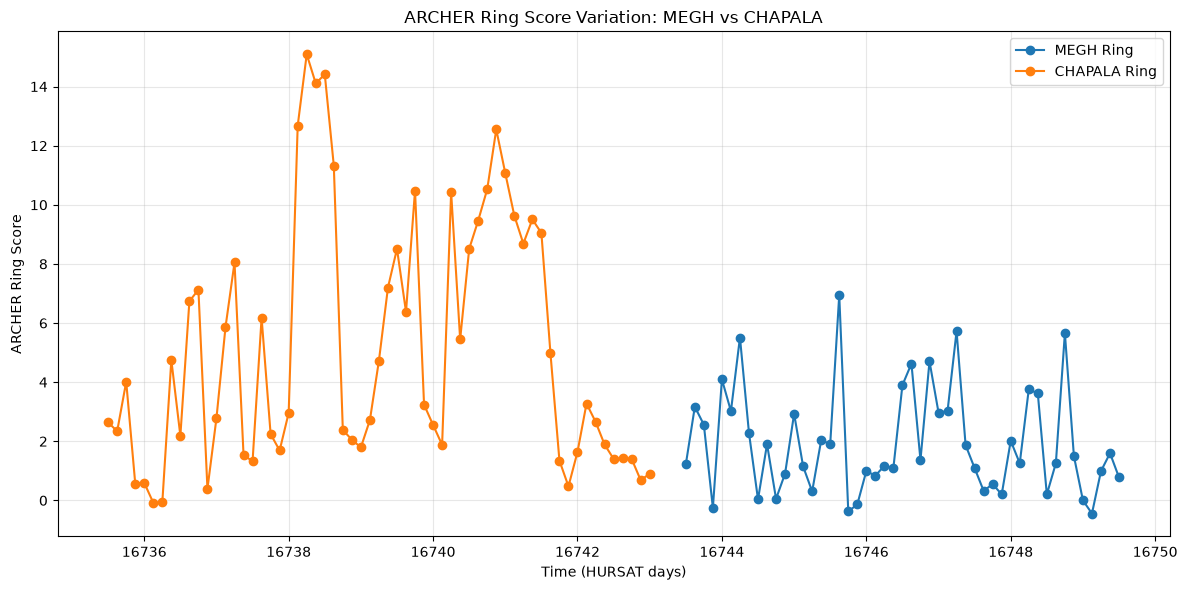

In [97]:
plt.figure(figsize=(12, 6))

plt.plot(
    megh_time,
    [float(r["archer_ring_score"]) for r in megh_analysis],
    marker="o",
    label="MEGH Ring"
)

plt.plot(
    chapala_time,
    [float(r["archer_ring_score"]) for r in chapala_analysis],
    marker="o",
    label="CHAPALA Ring"
)

plt.xlabel("Time (HURSAT days)")
plt.ylabel("ARCHER Ring Score")
plt.title("ARCHER Ring Score Variation: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [98]:
def calculate_archer_correlations(data, cyclone_name):
    wind = np.array([float(r["WindSpd"]) for r in data])
    pressure = np.array([float(r["CentPrs"]) for r in data])
    combo = np.array([float(r["archer_combo_score"]) for r in data])
    ring = np.array([float(r["archer_ring_score"]) for r in data])

    print(f"\n{cyclone_name}")
    print("=" * 45)

    print("Combo Score vs Wind Speed:",
          round(np.corrcoef(combo, wind)[0, 1], 3))

    print("Combo Score vs Pressure:",
          round(np.corrcoef(combo, pressure)[0, 1], 3))

    print("Ring Score vs Wind Speed:",
          round(np.corrcoef(ring, wind)[0, 1], 3))

    print("Ring Score vs Pressure:",
          round(np.corrcoef(ring, pressure)[0, 1], 3))


calculate_archer_correlations(megh_analysis, "MEGH")
calculate_archer_correlations(chapala_analysis, "CHAPALA")


MEGH
Combo Score vs Wind Speed: 0.142
Combo Score vs Pressure: -0.156
Ring Score vs Wind Speed: 0.167
Ring Score vs Pressure: -0.179

CHAPALA
Combo Score vs Wind Speed: -0.435
Combo Score vs Pressure: 0.433
Ring Score vs Wind Speed: 0.601
Ring Score vs Pressure: -0.604


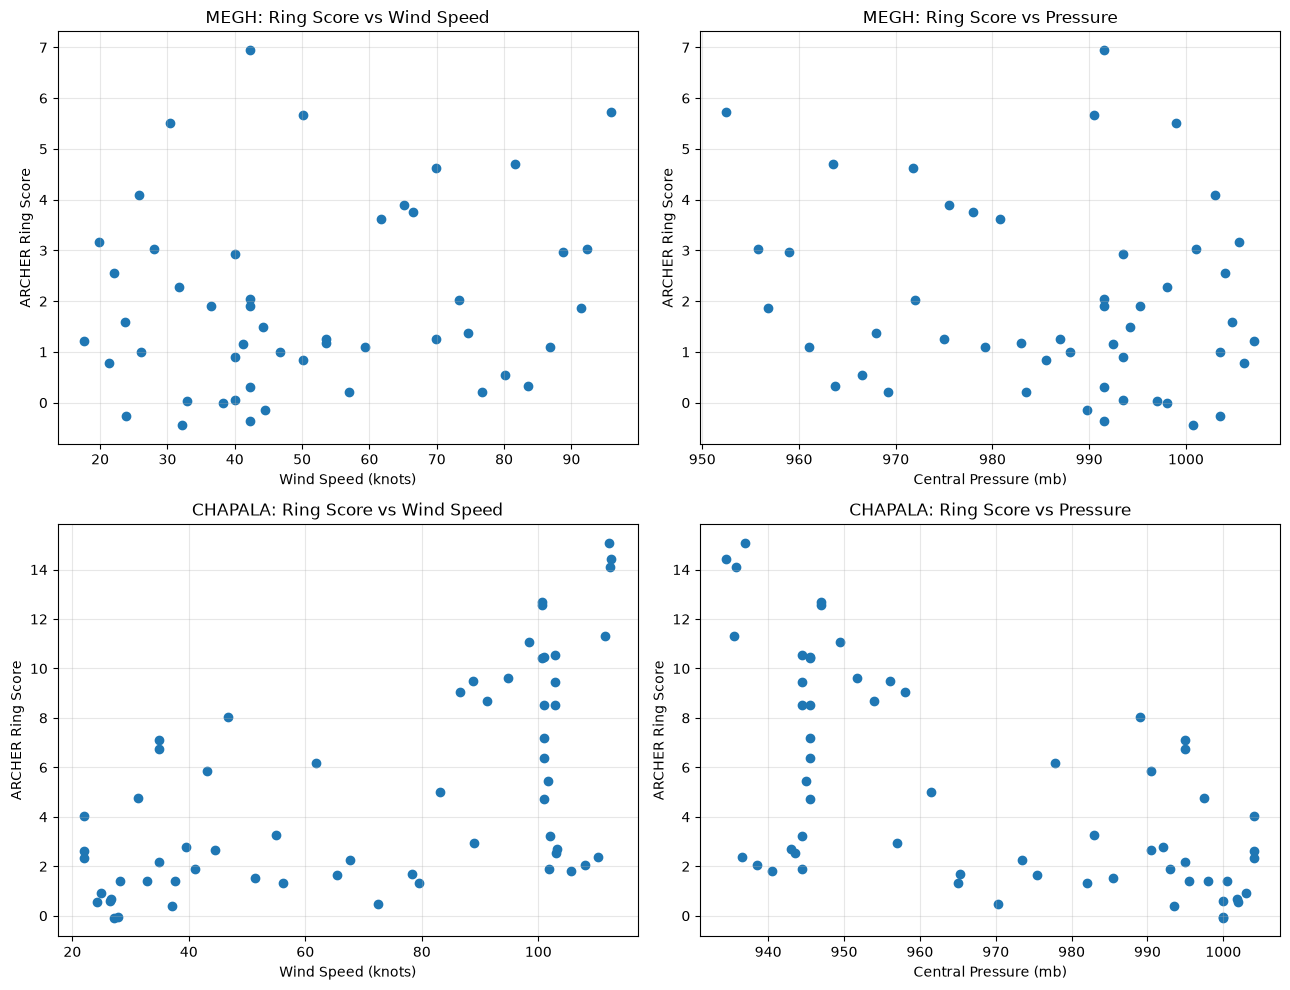

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

datasets = [
    (megh_analysis, "MEGH", axes[0, 0], axes[0, 1]),
    (chapala_analysis, "CHAPALA", axes[1, 0], axes[1, 1])
]

for data, name, wind_ax, pressure_ax in datasets:

    combo = np.array([
        float(r["archer_combo_score"]) for r in data
    ])

    ring = np.array([
        float(r["archer_ring_score"]) for r in data
    ])

    wind = np.array([
        float(r["WindSpd"]) for r in data
    ])

    pressure = np.array([
        float(r["CentPrs"]) for r in data
    ])

    wind_ax.scatter(wind, ring)
    wind_ax.set_title(f"{name}: Ring Score vs Wind Speed")
    wind_ax.set_xlabel("Wind Speed (knots)")
    wind_ax.set_ylabel("ARCHER Ring Score")
    wind_ax.grid(True, alpha=0.3)

    pressure_ax.scatter(pressure, ring)
    pressure_ax.set_title(f"{name}: Ring Score vs Pressure")
    pressure_ax.set_xlabel("Central Pressure (mb)")
    pressure_ax.set_ylabel("ARCHER Ring Score")
    pressure_ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [103]:
def average_ranks(values):
    values = np.asarray(values)
    order = np.argsort(values)
    sorted_values = values[order]

    ranks = np.empty(len(values), dtype=float)

    i = 0
    while i < len(values):
        j = i + 1

        while j < len(values) and sorted_values[j] == sorted_values[i]:
            j += 1

        average_rank = (i + 1 + j) / 2
        ranks[order[i:j]] = average_rank

        i = j

    return ranks


def calculate_spearman(x, y):
    rank_x = average_ranks(x)
    rank_y = average_ranks(y)

    return np.corrcoef(rank_x, rank_y)[0, 1]

In [104]:
analyse_spearman(megh_analysis, "MEGH")
analyse_spearman(chapala_analysis, "CHAPALA")


MEGH
Combo vs Wind: 0.046
Combo vs Pressure: -0.064
Ring vs Wind: 0.152
Ring vs Pressure: -0.163

CHAPALA
Combo vs Wind: -0.402
Combo vs Pressure: 0.385
Ring vs Wind: 0.573
Ring vs Pressure: -0.572


In [105]:
sample_file = nc_files[0]

with pyfive.File(sample_file, "r") as ds:
    for field in ["archer_combo_score", "archer_ring_score"]:
        print(f"\n{field}")
        print(ds[field].attrs)


archer_combo_score
{'long_name': array([b'Combined score when determining storm center from ARCHER v2.0 '],
      dtype=object), 'units': array([b'1'], dtype=object), 'DIMENSION_LIST': array([array([<pyfive.core.Reference object at 0x000001B20D74C0F0>], dtype=object)],
      dtype=object), '_Netcdf4Dimid': np.int32(2)}

archer_ring_score
{'long_name': array([b'Ring score when determining storm center from ARCHER v2.0 '],
      dtype=object), 'units': array([b'1'], dtype=object), 'Note': array([b'The spiral score is the difference between archer_combo_score and archer_ring_score'],
      dtype=object), 'DIMENSION_LIST': array([array([<pyfive.core.Reference object at 0x000001B20D74C2D0>], dtype=object)],
      dtype=object), '_Netcdf4Dimid': np.int32(2)}


In [106]:
def calculate_spiral_statistics(data, cyclone_name):
    combo = np.array([
        float(r["archer_combo_score"]) for r in data
    ])

    ring = np.array([
        float(r["archer_ring_score"]) for r in data
    ])

    spiral = combo - ring

    print(f"\n{cyclone_name}")
    print("=" * 40)
    print("Minimum spiral score:", round(spiral.min(), 3))
    print("Maximum spiral score:", round(spiral.max(), 3))
    print("Average spiral score:", round(spiral.mean(), 3))


calculate_spiral_statistics(megh_analysis, "MEGH")
calculate_spiral_statistics(chapala_analysis, "CHAPALA")


MEGH
Minimum spiral score: -1.227
Maximum spiral score: 10.553
Average spiral score: 5.366

CHAPALA
Minimum spiral score: -9.84
Maximum spiral score: 8.51
Average spiral score: 1.394


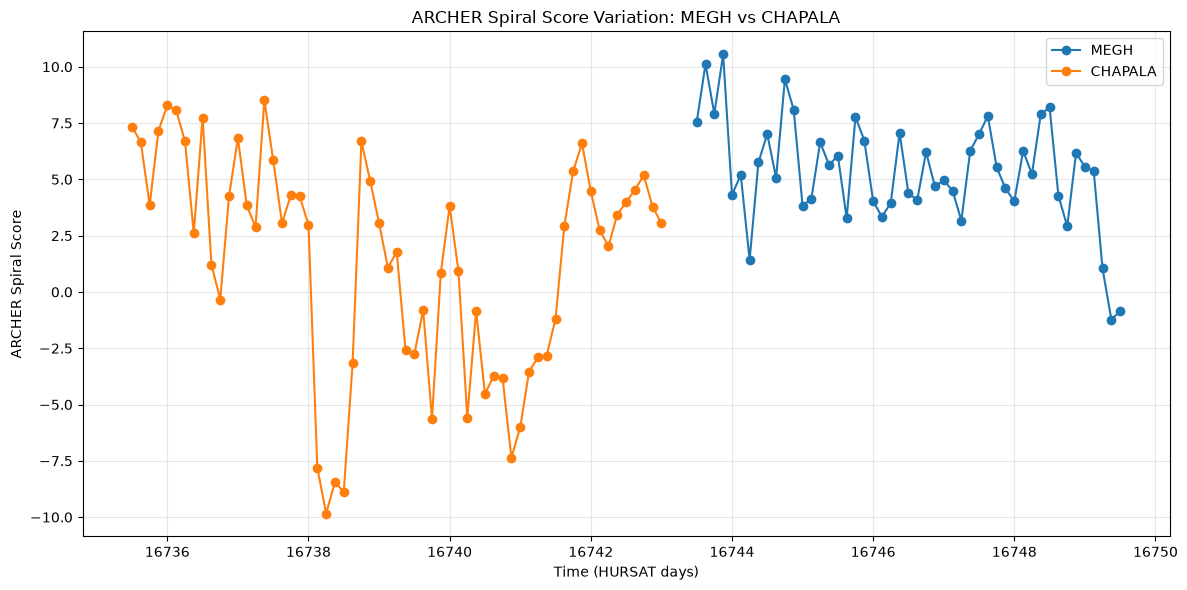

In [107]:
plt.figure(figsize=(12, 6))

megh_spiral = [
    float(r["archer_combo_score"]) -
    float(r["archer_ring_score"])
    for r in megh_analysis
]

chapala_spiral = [
    float(r["archer_combo_score"]) -
    float(r["archer_ring_score"])
    for r in chapala_analysis
]

plt.plot(
    megh_time, megh_spiral,
    marker="o", label="MEGH"
)

plt.plot(
    chapala_time, chapala_spiral,
    marker="o", label="CHAPALA"
)

plt.xlabel("Time (HURSAT days)")
plt.ylabel("ARCHER Spiral Score")
plt.title("ARCHER Spiral Score Variation: MEGH vs CHAPALA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()